# 02 Localization and first damage models

**Notebook 2 of 6, xBD building damage assessment**

Three models on 256x256 crops cut live from the full images:

| model | input | output |
|---|---|---|
| UNet1 | pre (3 channels) | building yes/no |
| variant A | pre, post, building mask (7 channels) | background / building / damaged |
| variant B | pre, post (6 channels) | background / building / damaged |

The damage models run on a subset of events here (hurricanes from train,
tornadoes from tier3); notebook 3 scales to all events.

Requires `01_data_check.ipynb` to have run once, so the Tier3 targets exist.

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "config.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
from PIL import Image
import matplotlib.pyplot as pl
import torch
from torch.utils.data import DataLoader

import config
from common import data, crops, models, losses, train, evaluate, plots

pl.rcParams["figure.dpi"] = 120
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

paths = {split: found for split, found in data.resolve_splits(config.DATA_ROOT).items()
         if split in ("train", "test", "tier3")}
file_lists = {split: data.list_pre_images(paths[split]["images"]) for split in paths}
for split, files in file_lists.items():
    print(f"{split}: {len(files)} pre-disaster images")


/DATA/schrepel/ml_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
train: 2746 pre-disaster images
test: 917 pre-disaster images
tier3: 6288 pre-disaster images


## 1. Data

Images without a meaningful building area are dropped. Training runs on train
and tier3, validation on test.

In [2]:
all_building_files = []
for split in paths:
    for pre_image in file_lists[split]:
        stem = pre_image.replace("_pre_disaster.png", "")
        target = np.array(Image.open(
            os.path.join(paths[split]["targets"], f"{stem}_pre_disaster_target.png")))
        if (target > 0).mean() >= config.MIN_BUILDING_FRACTION:
            all_building_files.append((split, stem))

train_files = [(s, stem) for s, stem in all_building_files if s in ("train", "tier3")]
val_files = [(s, stem) for s, stem in all_building_files if s == "test"]

print(f"{len(train_files)} training images, {len(val_files)} validation images")

4836 training images, 676 validation images


## 2. Cropping and datasets

## 3. Model, losses and training loop

One `UNet` class for all three models, only `in_channels` and `out_channels`
differ. The training loop is shared as well and is reused in the later
notebooks.

## 4. Fixed validation tiles for localization

The random draw happens once and is stored in `val_tiles/`, so every model is
scored on exactly the same crops.

In [3]:
VAL_TILES_PATH = config.VAL_TILES_DIR / "val_tiles_fixed.pt"

if not VAL_TILES_PATH.exists():
    np.random.seed(357)
    tiles = []
    for split, stem in val_files:
        image = np.array(Image.open(
            os.path.join(paths[split]["images"], f"{stem}_pre_disaster.png")))
        target = np.array(Image.open(
            os.path.join(paths[split]["targets"], f"{stem}_pre_disaster_target.png")))
        for _ in range(config.N_VAL_CROPS_PER_IMAGE):
            tile_image, tile_target, is_negative = crops.sample_tile(image, target)
            image_t, target_t = crops.to_tensor(tile_image, tile_target)
            tiles.append((image_t, target_t, int(is_negative)))

    torch.save(tiles, VAL_TILES_PATH)
    print(f"saved {len(tiles)} tiles to {VAL_TILES_PATH}")

In [4]:
val_tiles = train.load_val_tiles("val_tiles_fixed.pt")
n_negative = sum(t[2] for t in val_tiles)
print(f"{100 * (len(val_tiles) - n_negative) / len(val_tiles):.1f}% positive")

val_loader = DataLoader(crops.FixedTileDataset(val_tiles), batch_size=config.BATCH_SIZE, shuffle=False)

loaded /DATA/schrepel/xbd_new/val_tiles/val_tiles_fixed.pt (5408 tiles)
82.8% positive


## 5. UNet1: building localization

Segments buildings from the pre-disaster image.

In [5]:
if not (config.CKPT_DIR / "unet_localization_best.pt").exists():
    train_loader_localization = DataLoader(
        crops.BuildingDataset(train_files, paths, n_crops=8, augment=True),
        batch_size=config.BATCH_SIZE, shuffle=True, num_workers=4,
        pin_memory=(device.type == "cuda"))

    torch.manual_seed(357)
    model_localization = models.UNet(in_channels=3, out_channels=2, base_filters=64, dropout_p=0.2).to(device)

    train.train_model(model_localization, train_loader_localization, [val_loader],
                config.EPOCHS, config.LEARNING_RATE, device,
                config.CKPT_DIR / "unet_localization_best.pt", config.HISTORY_DIR / "history_localization.pt",
                loss_fn=losses.BCEDiceLoss(dice_weight=0.5))

In [6]:
model_localization = models.UNet(in_channels=3, out_channels=2, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_localization, "unet_localization_best.pt", device)

loaded /DATA/schrepel/xbd_new/checkpoints/unet_localization_best.pt


UNet(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (block): S

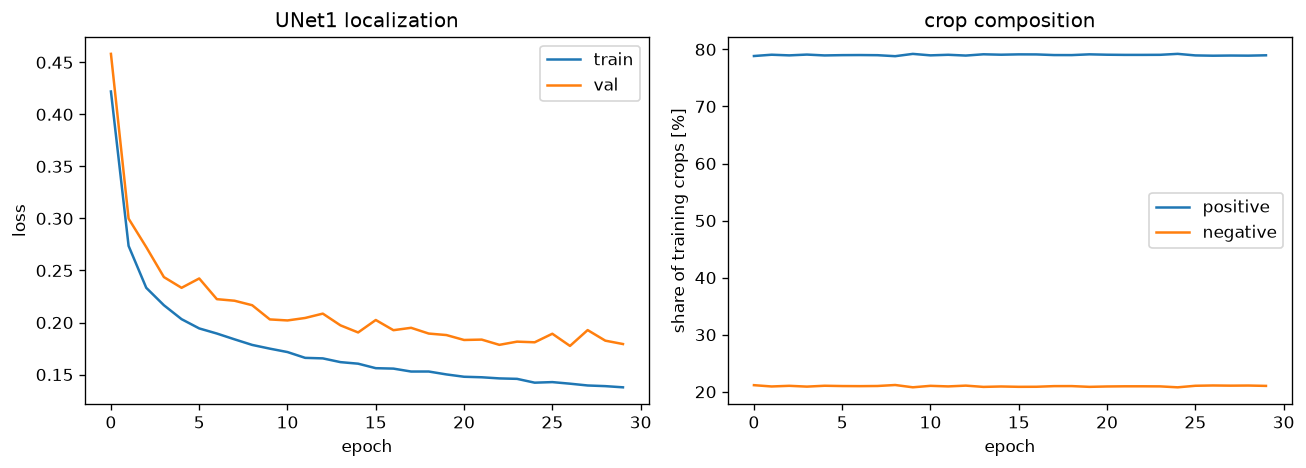

In [7]:
plots.plot_history(train.load_history("history_localization.pt"), "UNet1 localization")

In [8]:
results_localization = evaluate.per_class_metrics(model_localization, val_loader, 2, device)
evaluate.print_metrics(results_localization, config.LOCALIZATION_NAMES, "UNet1 localization")

UNet1 localization
       class   precision    recall      F1
  background       0.979     0.986   0.983
    building       0.886     0.837   0.861


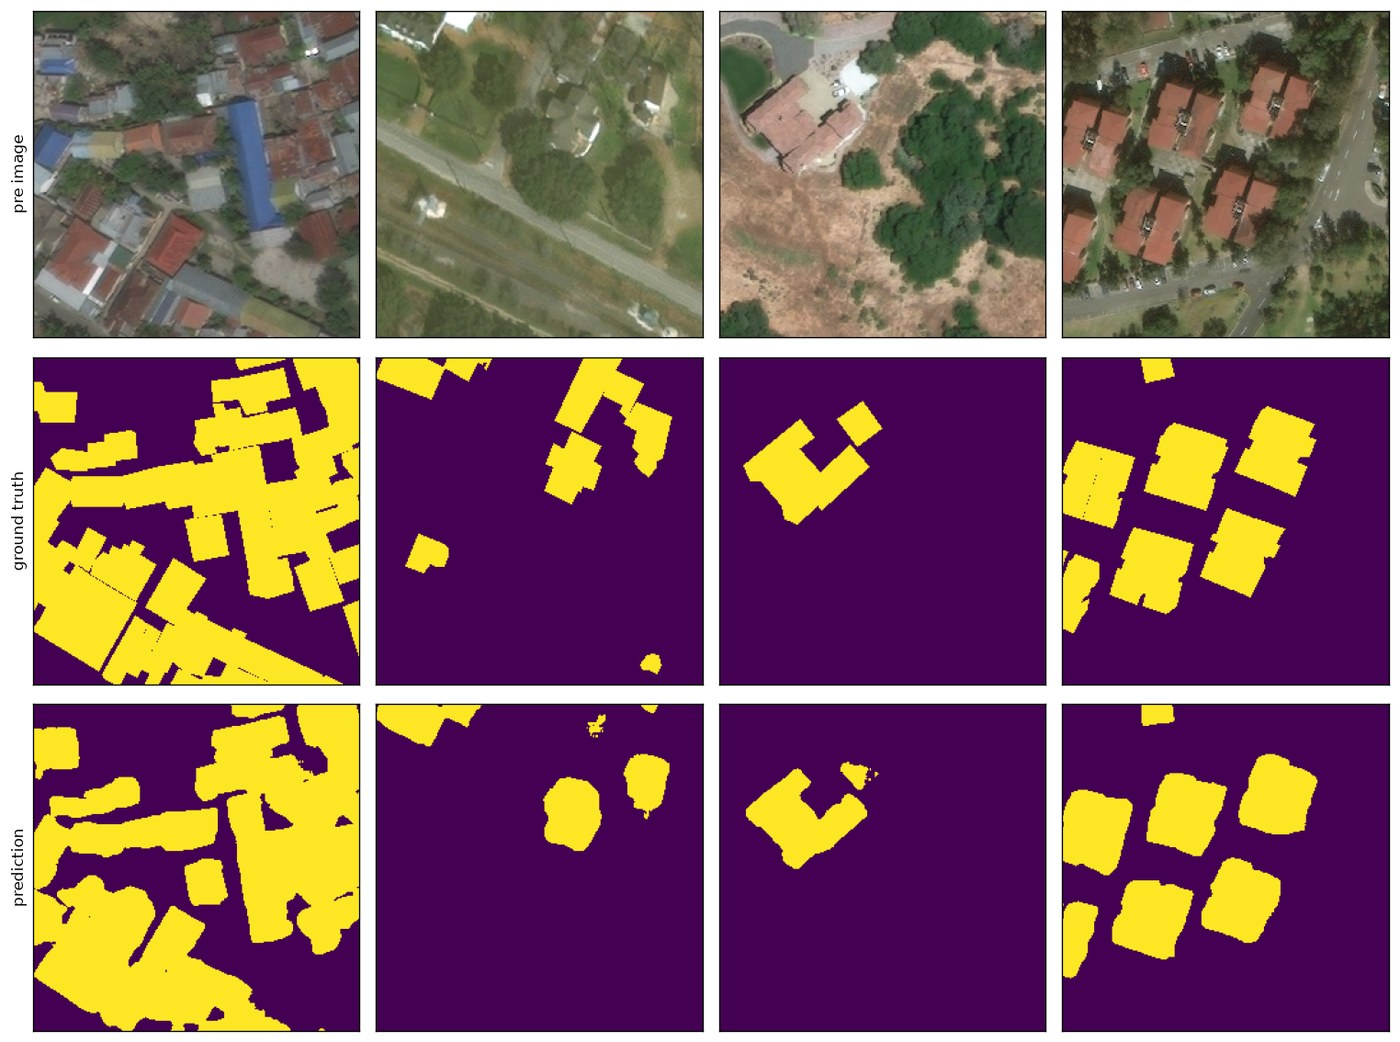

In [9]:
indices = np.random.choice(len(val_tiles), 4, replace=False)

fig, ax = pl.subplots(3, 4, figsize=(12.8, 9.6))
for col, index in enumerate(indices):
    image, target, _ = val_tiles[index]
    with torch.no_grad():
        prediction = model_localization(image.unsqueeze(0).to(device)).argmax(dim=1)[0].cpu()

    ax[0, col].imshow(image.permute(1, 2, 0))
    ax[1, col].imshow(target, cmap="viridis", vmin=0, vmax=1)
    ax[2, col].imshow(prediction, cmap="viridis", vmin=0, vmax=1)
    for row in range(3):
        ax[row, col].set_xticks([])
        ax[row, col].set_yticks([])

for row, label in enumerate(["pre image", "ground truth", "prediction"]):
    ax[row, 0].set_ylabel(label)

pl.tight_layout()
pl.show()

## 6. Damage data

The first damage models see hurricanes from train and tornadoes from tier3,
validated on the hurricanes in test. Both event types have a clear, visible
damage pattern, which keeps the problem narrow at this stage.

In [10]:
damage_train_files = data.stems_for_events(file_lists, "train", config.HURRICANE_EVENTS) + \
                     data.stems_for_events(file_lists, "tier3", config.TORNADO_EVENTS)
damage_val_files = data.stems_for_events(file_lists, "test", config.HURRICANE_EVENTS)

print(f"{len(damage_train_files)} training images, {len(damage_val_files)} validation images")

1906 training images, 383 validation images


The stored tiles are raw (pre image, post image, 0 to 4 target). The target
format is decided on access, so the three class variants here and the five class
models in notebook 3 are scored on identical crops.

In [11]:
DAMAGE_VAL_TILES_PATH = config.VAL_TILES_DIR / "val_damage_raw_tiles.pt"

if not DAMAGE_VAL_TILES_PATH.exists():
    tiles = crops.draw_raw_tiles(damage_val_files, paths, config.N_VAL_CROPS)
    torch.save(tiles, DAMAGE_VAL_TILES_PATH)
    print(f"saved {len(tiles)} tiles to {DAMAGE_VAL_TILES_PATH}")

In [12]:
val_damage_tiles = train.load_val_tiles("val_damage_raw_tiles.pt")
crops.describe_tiles(val_damage_tiles, "hurricane validation")

loaded /DATA/schrepel/xbd_new/val_tiles/val_damage_raw_tiles.pt (4596 tiles)


hurricane validation: 4596 tiles, 69.3% positive, 3.87% damaged building pixels


## 7. Variant A: with building mask

Input is pre, post and the building probability from UNet1, so 7 channels. The
mask is computed per tile inside the dataset.

In [13]:
val_loader_a = DataLoader(
    crops.FixedDamageDataset(val_damage_tiles, crops.damage_to_three_class,
                       building_model=model_localization, device=device),
    batch_size=config.BATCH_SIZE, shuffle=False)

if not (config.CKPT_DIR / "method_a_best.pt").exists():
    for p in model_localization.parameters():
        p.requires_grad = False
    model_localization.eval()

    # num_workers=0 because the dataset itself calls UNet1 on the GPU
    train_loader_a = DataLoader(
        crops.DamageDataset(damage_train_files, paths, crops.damage_to_three_class, n_crops=12,
                      augment=True, building_model=model_localization, device=device),
        batch_size=config.BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)

    torch.manual_seed(357)
    model_a = models.UNet(in_channels=7, out_channels=3, base_filters=64, dropout_p=0.2).to(device)

    train.train_model(model_a, train_loader_a, [val_loader_a], config.EPOCHS, config.LEARNING_RATE, device,
                config.CKPT_DIR / "method_a_best.pt", config.HISTORY_DIR / "history_a.pt",
                loss_fn=losses.MultiClassDiceLoss(n_classes=3, dice_weight=0.5))

In [14]:
model_a = models.UNet(in_channels=7, out_channels=3, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_a, "method_a_best.pt", device)

loaded /DATA/schrepel/xbd_new/checkpoints/method_a_best.pt


UNet(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(7, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (block): S

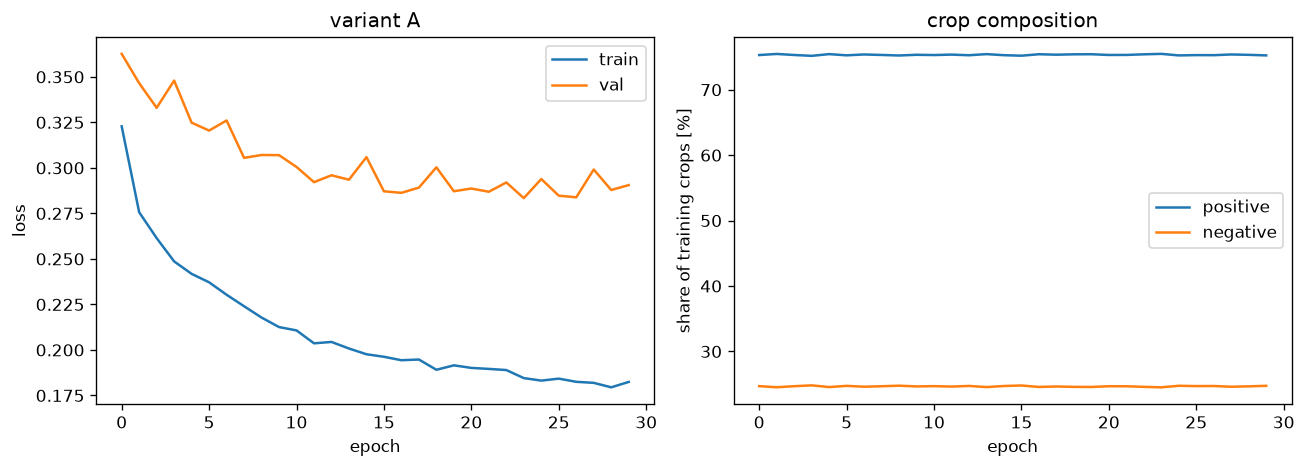

In [15]:
plots.plot_history(train.load_history("history_a.pt"), "variant A")

In [16]:
results_a = evaluate.per_class_metrics(model_a, val_loader_a, 3, device)
evaluate.print_metrics(results_a, config.THREE_CLASS_NAMES, "variant A")

variant A
       class   precision    recall      F1
  background       0.984     0.991   0.987
    building       0.761     0.728   0.744
     damaged       0.743     0.647   0.692


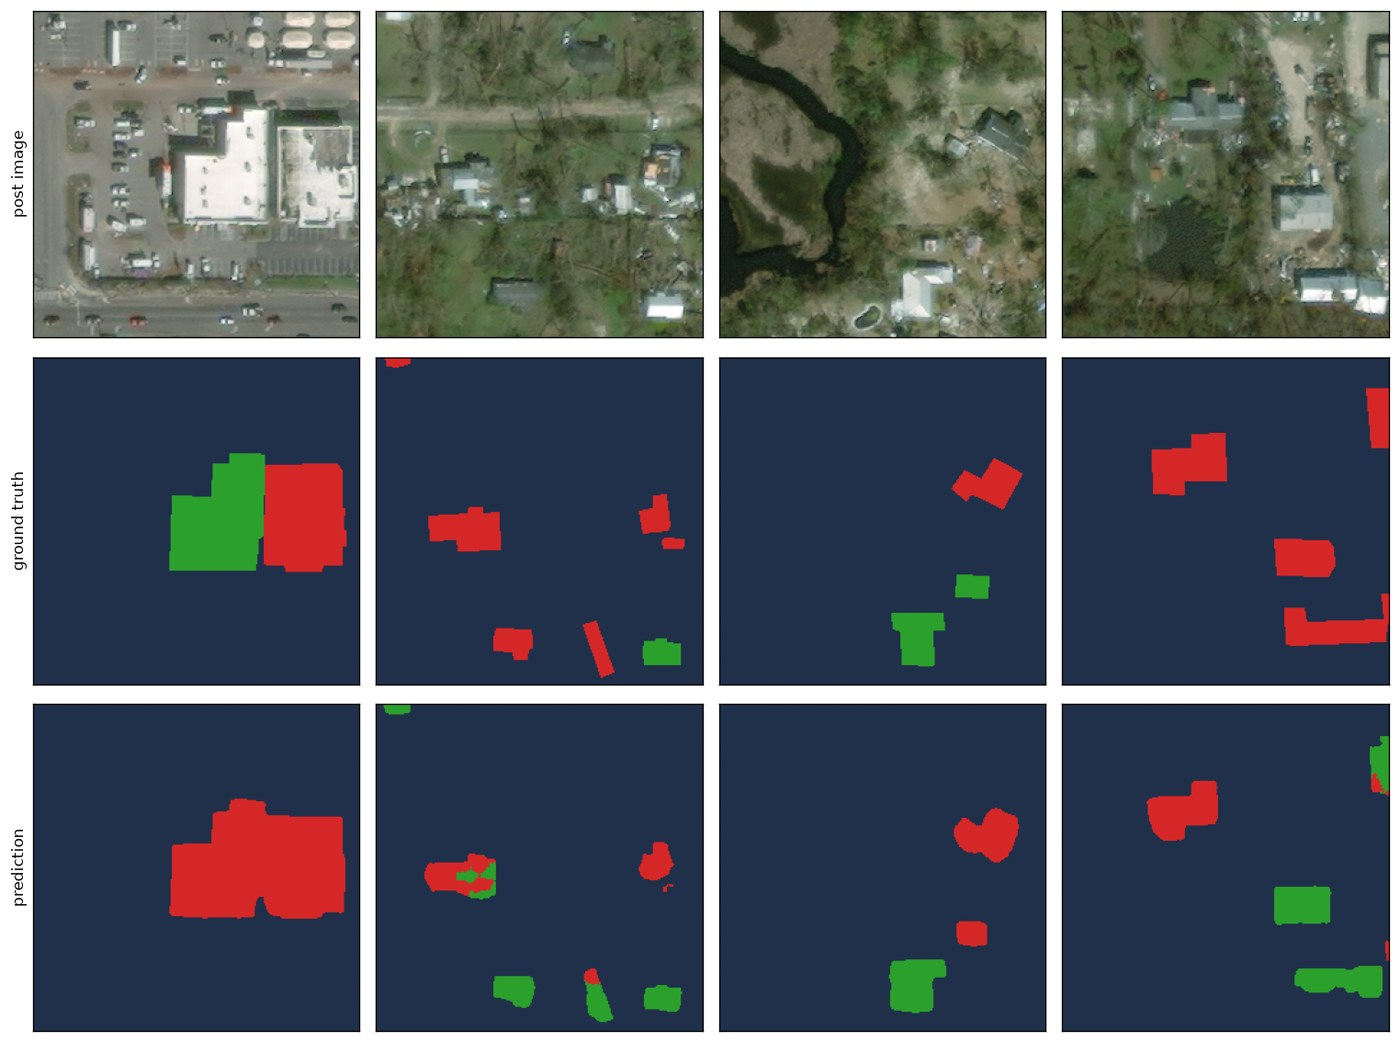

In [17]:
plots.show_examples(plots.make_predictor(model_a, device, building_model=model_localization),
              val_damage_tiles, crops.damage_to_three_class, plots.THREE_CLASS_CMAP, n_classes=3)

## 8. Variant B: without building mask

Same target, but the input is only pre and post, so 6 channels.

In [18]:
val_loader_b = DataLoader(
    crops.FixedDamageDataset(val_damage_tiles, crops.damage_to_three_class),
    batch_size=config.BATCH_SIZE, shuffle=False)

if not (config.CKPT_DIR / "method_b_best.pt").exists():
    train_loader_b = DataLoader(
        crops.DamageDataset(damage_train_files, paths, crops.damage_to_three_class,
                      n_crops=12, augment=True),
        batch_size=config.BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)

    torch.manual_seed(357)
    model_b = models.UNet(in_channels=6, out_channels=3, base_filters=64, dropout_p=0.2).to(device)

    train.train_model(model_b, train_loader_b, [val_loader_b], config.EPOCHS, config.LEARNING_RATE, device,
                config.CKPT_DIR / "method_b_best.pt", config.HISTORY_DIR / "history_b.pt",
                loss_fn=losses.MultiClassDiceLoss(n_classes=3, dice_weight=0.5))

In [19]:
model_b = models.UNet(in_channels=6, out_channels=3, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_b, "method_b_best.pt", device)

loaded /DATA/schrepel/xbd_new/checkpoints/method_b_best.pt


UNet(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(6, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (block): S

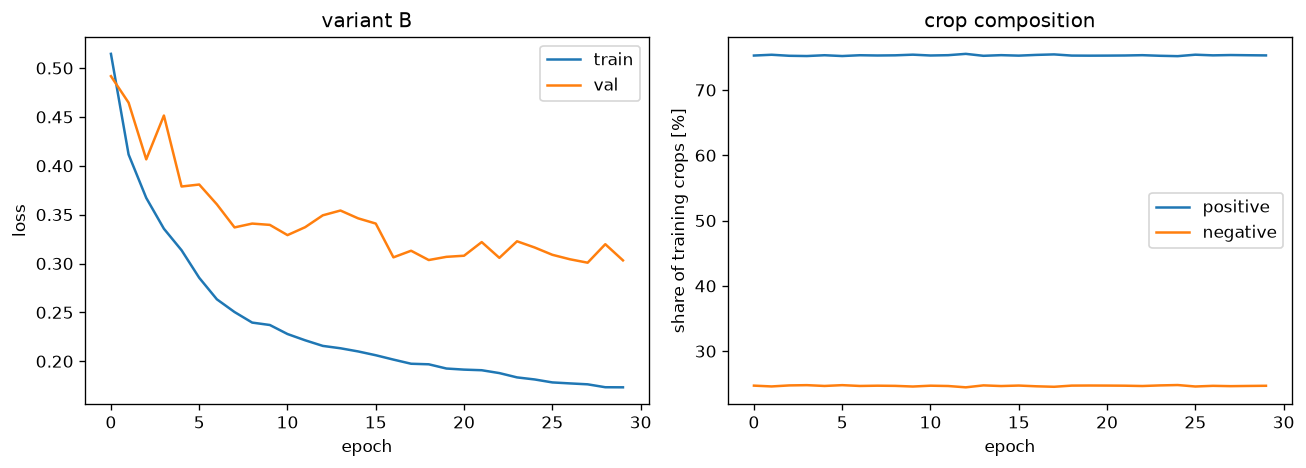

In [20]:
plots.plot_history(train.load_history("history_b.pt"), "variant B")

In [21]:
results_b = evaluate.per_class_metrics(model_b, val_loader_b, 3, device)
evaluate.print_metrics(results_b, config.THREE_CLASS_NAMES, "variant B")

variant B
       class   precision    recall      F1
  background       0.983     0.989   0.986
    building       0.757     0.693   0.724
     damaged       0.703     0.675   0.689


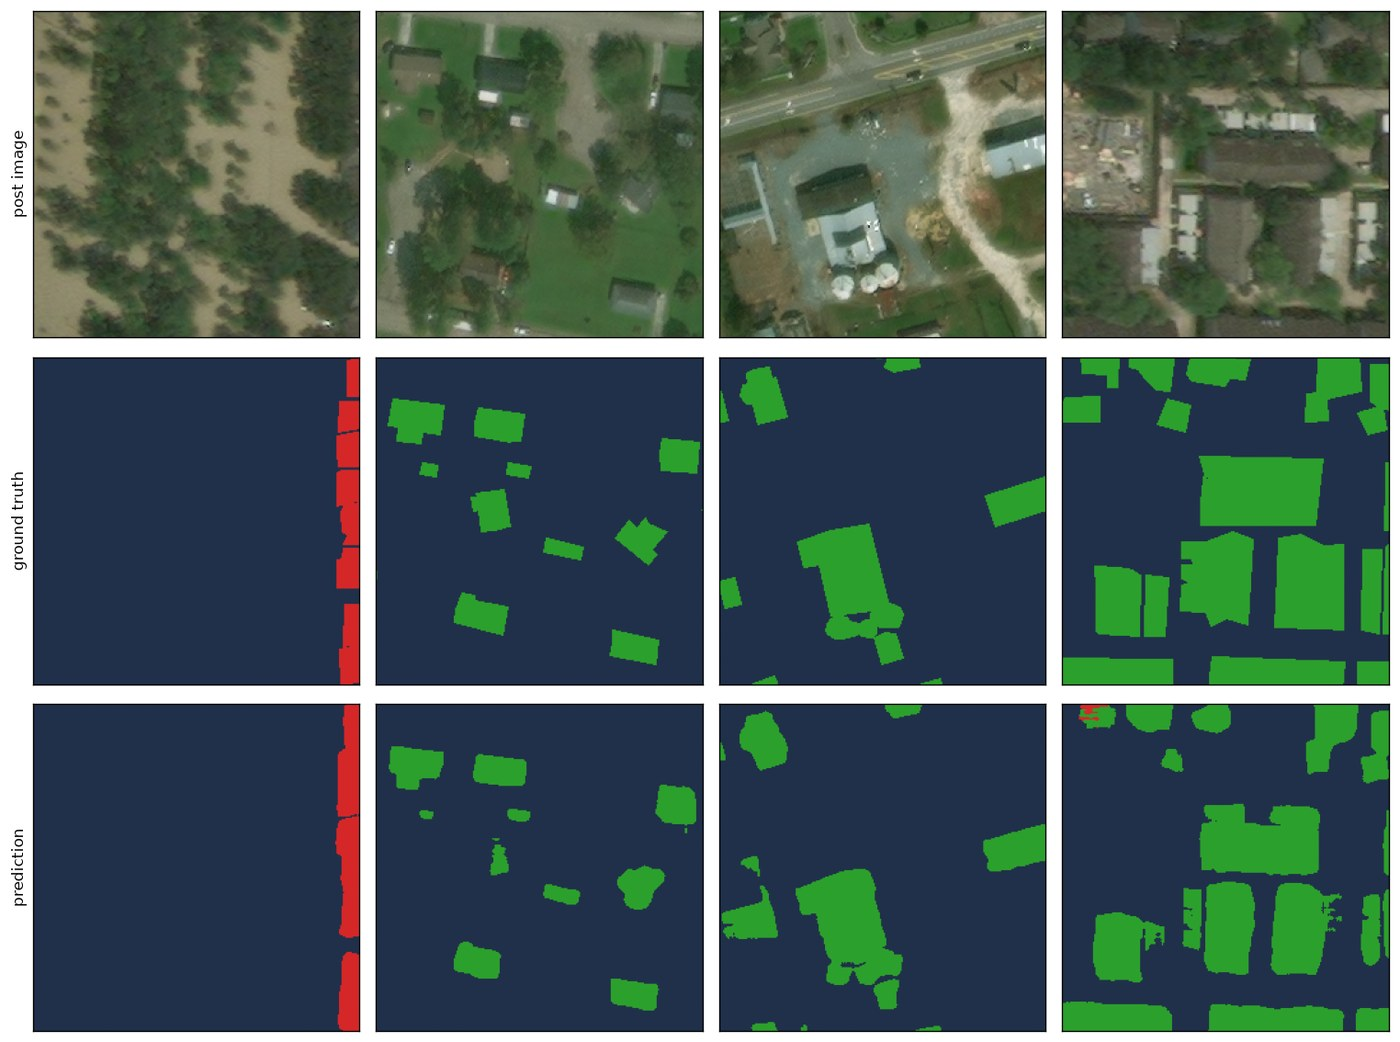

In [22]:
plots.show_examples(plots.make_predictor(model_b, device), val_damage_tiles,
              crops.damage_to_three_class, plots.THREE_CLASS_CMAP, n_classes=3)

## 9. A against B

In [23]:
comparison = {"A (7 channels)": results_a, "B (6 channels)": results_b}

header = f"{'variant':<18s}" + "".join(f"{config.THREE_CLASS_NAMES[c]:>12s}" for c in range(3))
print("F1 per class")
print(header)
for name, results in comparison.items():
    print(f"{name:<18s}" + "".join(f"{results[c][2]:>12.3f}" for c in range(3)))

F1 per class
variant             background    building     damaged
A (7 channels)           0.987       0.744       0.692
B (6 channels)           0.986       0.724       0.689


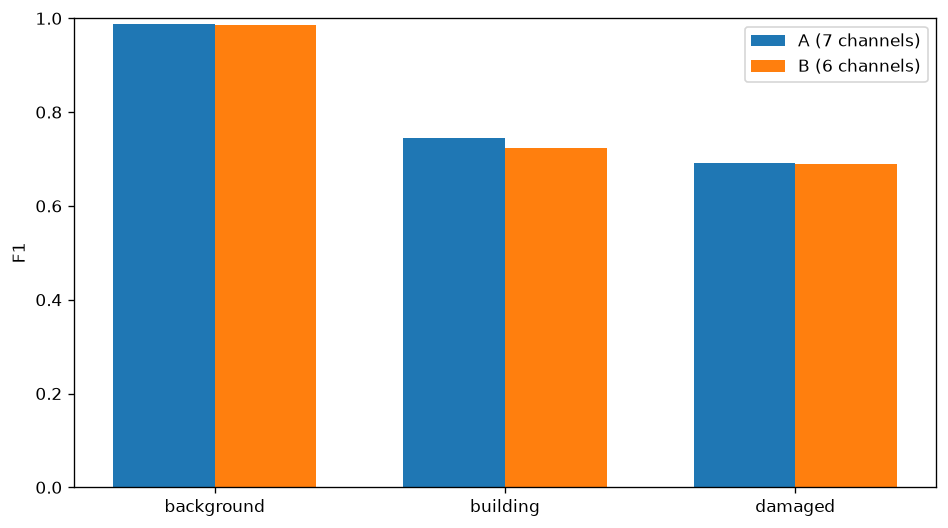

In [24]:
x = np.arange(3)
width = 0.35

pl.figure(figsize=(8, 4.5))
for offset, (name, results), color in zip([-width / 2, width / 2], comparison.items(), ["C0", "C1"]):
    pl.bar(x + offset, [results[c][2] for c in range(3)], width, label=name, color=color)

pl.xticks(x, [config.THREE_CLASS_NAMES[c] for c in range(3)])
pl.ylabel("F1")
pl.ylim(0, 1)
pl.legend()
pl.tight_layout()
pl.show()